In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import random
from PIL import Image

sys.path.append("../src")

from preprocess import (
    DATASET_DIR,
    TRAIN_DIR,
    TEST_DIR,
    UNCLEAN_DIR,
    IMAGE_EXTENSIONS,
    get_image_files,
    build_hash_index,
    find_duplicate_groups,
    find_cross_dataset_duplicates,
    audit_image_file,
    add_hash_column,
    find_too_small_images,
    add_aspect_ratio,
    build_hash_label_index,
    find_label_conflicts,
    build_cleaning_report,
    clean_unclean_dataset,
    create_merged_train_dataset,
    get_class_counts,
)

### Dataset Overview

In [2]:
train_files = get_image_files(TRAIN_DIR)
test_files = get_image_files(TEST_DIR)
unclean_files = get_image_files(UNCLEAN_DIR)

print("Dataset:", DATASET_DIR.resolve())
print("Train:", len(train_files))
print("Test:", len(test_files))
print("Unclean:", len(unclean_files))

Dataset: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset
Train: 1932
Test: 400
Unclean: 2026


### Hash Index

In [3]:
unclean_hashes = build_hash_index(UNCLEAN_DIR)
train_hashes = build_hash_index(TRAIN_DIR)
test_hashes = build_hash_index(TEST_DIR)

print("Unique hashes:")
print("  Unclean:", len(unclean_hashes))
print("  Train:  ", len(train_hashes))
print("  Test:   ", len(test_hashes))

Unique hashes:
  Unclean: 2026
  Train:   1932
  Test:    400


### Duplicates in Unclean

In [4]:
unclean_duplicates = find_duplicate_groups(
    unclean_hashes
)

print(
    "Duplicate groups inside unclean:",
    len(unclean_duplicates)
)

for md5, files in unclean_duplicates.items():

    print("\nMD5:", md5)

    for file in files:
        print(" ", file)

Duplicate groups inside unclean: 0


### Train and Unclean Duplicates

In [5]:
unclean_train_duplicates = (
    find_cross_dataset_duplicates(
        unclean_hashes,
        train_hashes
    )
)

print(
    "Duplicates between unclean and train:",
    len(unclean_train_duplicates)
)

for unclean_file, train_file in unclean_train_duplicates:

    print("\nUNCLEAN:", unclean_file)
    print("TRAIN:  ", train_file)

Duplicates between unclean and train: 16

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\199984667.jpg
TRAIN:   D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\train\ambulance\199984667.jpg

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\206808986.jpg
TRAIN:   D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\train\ambulance\206808986.jpg

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\208738861.jpg
TRAIN:   D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\train\ambulance\208738861.jpg

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\213342200.jpg
TRAIN:   D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\train\ambulance\213342200.jpg

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\213801906.jpg
TRAIN:   D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\train\ambulance\21380190

### Test and Unclean Duplicates

In [6]:
unclean_test_duplicates = (
    find_cross_dataset_duplicates(
        unclean_hashes,
        test_hashes
    )
)

print(
    "Duplicates between unclean and test:",
    len(unclean_test_duplicates)
)

for unclean_file, test_file in unclean_test_duplicates:

    print("\nUNCLEAN:", unclean_file)
    print("TEST:   ", test_file)

Duplicates between unclean and test: 8

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\200396165.jpg
TEST:    D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\ambulance\200396165.jpg

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\214830125.jpg
TEST:    D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\ambulance\214830125.jpg

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\215713763.jpg
TEST:    D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\ambulance\215713763.jpg

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\216095686.jpg
TEST:    D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\ambulance\216095686.jpg

UNCLEAN: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\unclean\ambulance\217040489.jpg
TEST:    D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\ambulance\217040489.jpg



### Label Conflicts

In [7]:
hash_to_files = build_hash_label_index(
    UNCLEAN_DIR
)

label_conflicts = find_label_conflicts(
    hash_to_files
)

print(
    "Number of label conflicts:",
    len(label_conflicts)
)

Number of label conflicts: 0


In [8]:
for md5, files in label_conflicts.items():

    print("\nMD5:", md5)

    for file_path, label in files:

        print(f"  Label: {label}")
        print(f"  File : {file_path}")

### Image Audit

In [9]:
unclean_audit = pd.DataFrame(
    [
        audit_image_file(path)
        for path in unclean_files
    ]
)

unclean_audit = add_hash_column(
    unclean_audit
)

print(
    "Number of files:",
    len(unclean_files)
)

print(
    "DataFrame shape:",
    unclean_audit.shape
)

unclean_audit.head()

Number of files: 2026
DataFrame shape: (2026, 9)


,path,extension,readable,format,width,height,mode,error,hash
0,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,273,331,RGB,None,37171f26efee91489e759bab458f1d08
1,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,315,373,RGB,None,3854d7b8bf3c7d17fe65b2710a6af299
2,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,287,355,RGB,None,1d7dab0bef9e5c7c388e52d668a93985
3,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,269,397,RGB,None,c8b7572f399aa7e3ad2cc8e864b40abf
4,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,302,339,RGB,None,9be8074fc014b90cb0d4ce4b869e2b5f


### Corrupted Files

In [10]:
bad_files = unclean_audit[
    ~unclean_audit["readable"]
]

print(
    "Unreadable / invalid files:",
    len(bad_files)
)

bad_files

Unreadable / invalid files: 0


,path,extension,readable,format,width,height,mode,error,hash


### Too Small Files

In [11]:
too_small = find_too_small_images(
    unclean_audit,
    min_width=32,
    min_height=32
)

print(
    "Too small:",
    len(too_small)
)

too_small

Too small: 0


,path,extension,readable,format,width,height,mode,error,hash


### Size Distribution

In [12]:
size_distribution = (
    unclean_audit[
        unclean_audit["readable"]
    ]
    .groupby(["width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values(
        "count",
        ascending=False
    )
)

size_distribution.head(20)

,width,height,count
114,198,264,73
71,186,252,64
83,189,252,62
144,207,276,40
48,177,240,39
105,198,252,33
61,180,240,30
78,189,240,29
165,210,276,24
67,186,240,22


### Aspect Ratio

In [13]:
valid = add_aspect_ratio(
    unclean_audit[
        unclean_audit["readable"]
    ]
)

valid["aspect_ratio"].describe()

count    2026.000000
mean        0.818249
std         0.119645
min         0.359882
25%         0.750000
50%         0.785714
75%         0.859254
max         1.378378
Name: aspect_ratio, dtype: float64

In [14]:
unusual_ratio = valid[
    (valid["aspect_ratio"] < 0.25) |
    (valid["aspect_ratio"] > 4)
]

unusual_ratio

,path,extension,readable,format,width,height,mode,error,hash,aspect_ratio


### Cleaning Report

In [15]:
cleaning_report = build_cleaning_report(
    unclean_audit,
    train_hashes,
    test_hashes
)

cleaning_report.head()

,path,extension,readable,format,width,height,mode,error,hash,class,duplicate_in_unclean,duplicate_in_train,duplicate_in_test
0,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,273,331,RGB,None,37171f26efee91489e759bab458f1d08,ambulance,False,False,False
1,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,315,373,RGB,None,3854d7b8bf3c7d17fe65b2710a6af299,ambulance,False,False,False
2,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,287,355,RGB,None,1d7dab0bef9e5c7c388e52d668a93985,ambulance,False,False,False
3,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,269,397,RGB,None,c8b7572f399aa7e3ad2cc8e864b40abf,ambulance,False,True,False
4,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,.jpg,True,JPEG,302,339,RGB,None,9be8074fc014b90cb0d4ce4b869e2b5f,ambulance,False,False,False


### Summary

In [16]:
print(
    "Duplicate in unclean:",
    cleaning_report[
        "duplicate_in_unclean"
    ].sum()
)

print(
    "Duplicate in train:",
    cleaning_report[
        "duplicate_in_train"
    ].sum()
)

print(
    "Duplicate in test:",
    cleaning_report[
        "duplicate_in_test"
    ].sum()
)

print(
    "Unreadable:",
    (~cleaning_report["readable"]).sum()
)

Duplicate in unclean: 0
Duplicate in train: 16
Duplicate in test: 8
Unreadable: 0


### Cleaning

In [17]:
CLEANED_UNCLEAN_DIR = (
    DATASET_DIR / "unclean_cleaned"
)

kept_files, removed_files = (
    clean_unclean_dataset(
        cleaning_report,
        train_hashes,
        test_hashes,
        CLEANED_UNCLEAN_DIR
    )
)

print("Kept:", len(kept_files))
print("Removed:", len(removed_files))

Kept: 2002
Removed: 24


### Cleaning decisions report

In [18]:
removal_report = pd.DataFrame(
    removed_files,
    columns=["path", "reason"]
)


removal_report.head(20)

,path,reason
0,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_train
1,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_test
2,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_train
3,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_train
4,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_train
5,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_train
6,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_test
7,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_test
8,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_test
9,D:\AI Bootcamp_M Sharif\traffic_vehicle_projec...,duplicate_in_train


In [19]:
removal_report["reason"].value_counts()

reason
duplicate_in_train    16
duplicate_in_test      8
Name: count, dtype: int64

### Merging

In [20]:
MERGED_DIR = (
    DATASET_DIR / "merged_train"
)

create_merged_train_dataset(
    TRAIN_DIR,
    CLEANED_UNCLEAN_DIR,
    MERGED_DIR
)

print(
    "Merged training dataset:",
    MERGED_DIR.resolve()
)

Merged training dataset: D:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\merged_train


### Final Class Count

In [21]:
class_counts = get_class_counts(
    MERGED_DIR
)

print(
    "Classes:",
    list(class_counts.keys())
)

for class_name, count in class_counts.items():

    print(
        f"{class_name:12s}: {count}"
    )

print(
    "\nNumber of classes:",
    len(class_counts)
)

Classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']
ambulance   : 361
autobus     : 470
kamyun      : 496
kamyunet    : 455
minibus     : 410
savari      : 500
taxi        : 493
vanet       : 749

Number of classes: 8


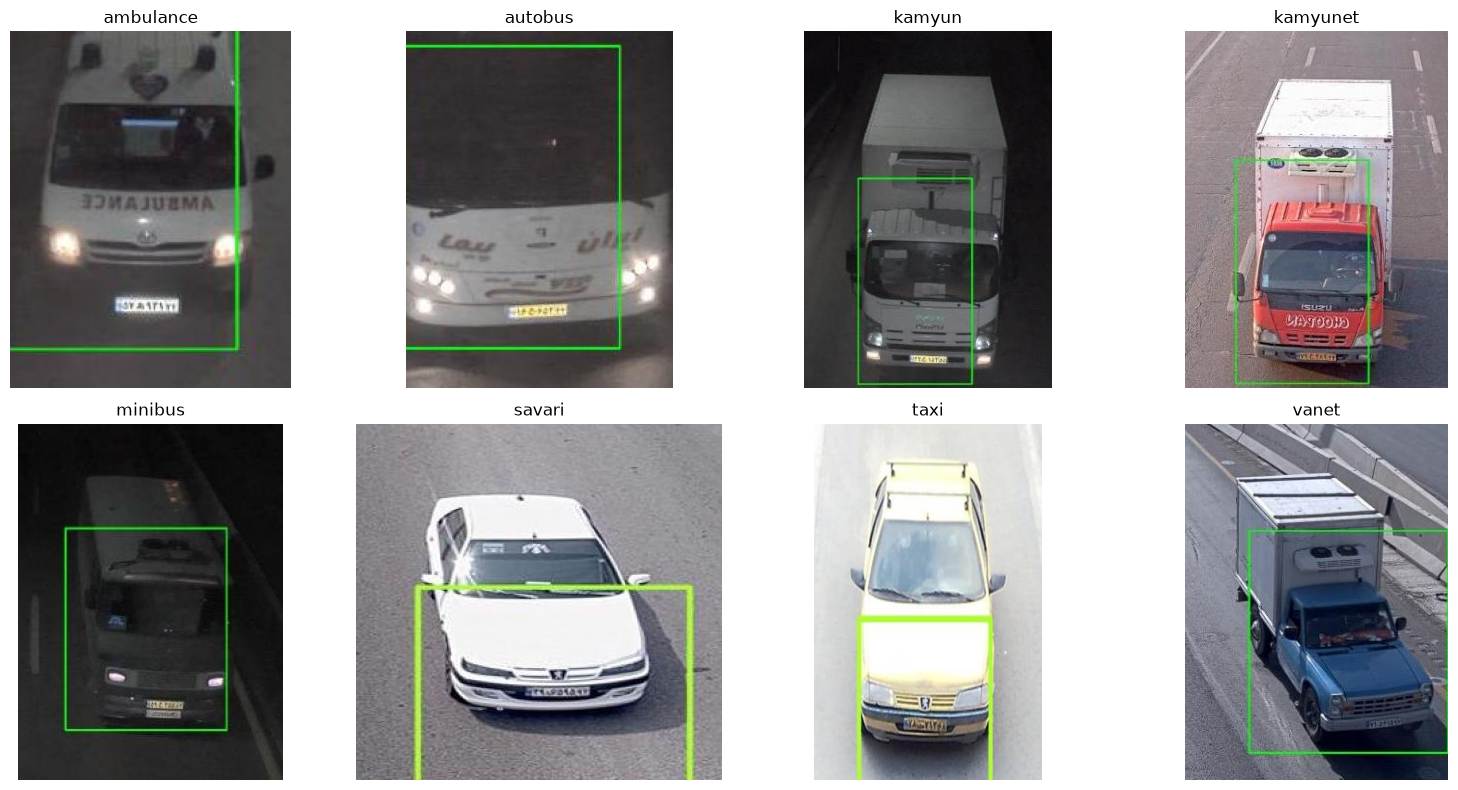

In [22]:
classes = [
    "ambulance",
    "autobus",
    "kamyun",
    "kamyunet",
    "minibus",
    "savari",
    "taxi",
    "vanet"
]

plt.figure(figsize=(16, 8))

for i, class_name in enumerate(classes):
    class_dir = TRAIN_DIR / class_name

    image_files = [
        p for p in class_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_path = random.choice(image_files)
    image = Image.open(image_path).convert("RGB")

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()